In [1]:
!pip install numpy torch torchvision matplotlib IPython optuna pandas

import math
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import optuna
from IPython import display as disp
import random
import os
import time

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # (this is related to setting the random seed so my results are reproducible)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')  # as taught, setting up on the uni's GPU

In [2]:
# I had to add this in to make my results reproducible for coursework submission
seed = 405
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

# I'm ensuring the dataloader workers get the same seed here
def seed_worker(worker_id):
    worker_seed = seed % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# and now the seed gets genarated
g = torch.Generator()
g.manual_seed(seed)

In [3]:
# Credit: Adapted from DL Coursework Template
# helper function to make getting another batch of data easier
def cycle(iterable):
    while True:
        for x in iterable:
            yield x

class_names = ['apple','aquarium_fish','baby','bear','beaver','bed','bee','beetle','bicycle','bottle','bowl','boy','bridge','bus','butterfly','camel','can','castle','caterpillar','cattle','chair','chimpanzee','clock','cloud','cockroach','couch','crab','crocodile','cup','dinosaur','dolphin','elephant','flatfish','forest','fox','girl','hamster','house','kangaroo','computer_keyboard','lamp','lawn_mower','leopard','lion','lizard','lobster','man','maple_tree','motorcycle','mountain','mouse','mushroom','oak_tree','orange','orchid','otter','palm_tree','pear','pickup_truck','pine_tree','plain','plate','poppy','porcupine','possum','rabbit','raccoon','ray','road','rocket','rose','sea','seal','shark','shrew','skunk','skyscraper','snail','snake','spider','squirrel','streetcar','sunflower','sweet_pepper','table','tank','telephone','television','tiger','tractor','train','trout','tulip','turtle','wardrobe','whale','willow_tree','wolf','woman','worm',]

# I've added augmenting to the train data to reduce overfitting
train_transform = torchvision.transforms.Compose([
    # I found this actually gives really sizeable gains
    torchvision.transforms.RandomCrop(32, padding=4), # this is like giving loads of additional variations of imgs
    torchvision.transforms.RandomHorizontalFlip(), # i.e. 50% chance of flipping imgs
    torchvision.transforms.ToTensor(),
])

train_loader = torch.utils.data.DataLoader(
    torchvision.datasets.CIFAR100('data', train=True, download=True, transform=train_transform),
    batch_size=64,
    drop_last=True,
    shuffle=True,
    num_workers=0,   # deterministic param for randomseed
    worker_init_fn=seed_worker, # ...and 2nd one
    generator=g # and then 3rd
)

# but I don't need to agument test data
test_loader = torch.utils.data.DataLoader(
    torchvision.datasets.CIFAR100('data', train=False, download=True, transform=torchvision.transforms.Compose([
        torchvision.transforms.ToTensor()
    ])),
    batch_size=64,
    drop_last=True,
    shuffle=False,
    num_workers=0, # again, setting the deterministic params for the randomseed
    worker_init_fn=seed_worker, 
    generator=g 
)

train_iterator = iter(cycle(train_loader))
test_iterator = iter(cycle(test_loader))

print(f'> Size of training dataset {len(train_loader.dataset)}')
print(f'> Size of test dataset {len(test_loader.dataset)}')

> Size of training dataset 50000
> Size of test dataset 10000


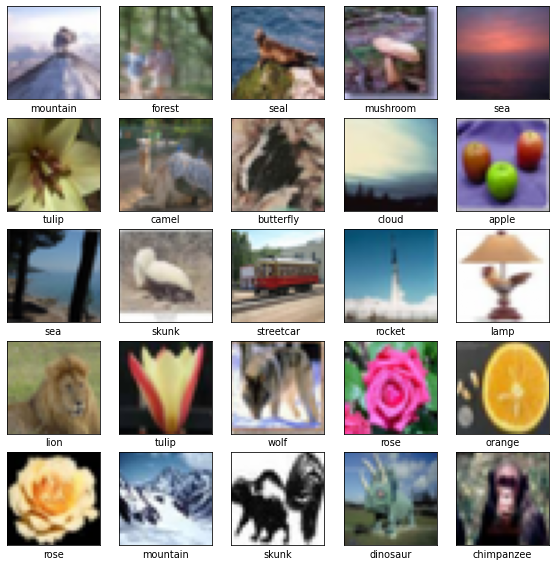

In [4]:
# Credit: DL Coursework Template
plt.rcParams['figure.dpi'] = 70
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    img = test_loader.dataset[i][0].numpy().transpose(1, 2, 0)
    plt.imshow(img)
    plt.xlabel(class_names[test_loader.dataset[i][1]])
plt.show()

# Plan
For this coursework I decided to base my inspiration of the set of MobileNet architectures (v1: https://arxiv.org/pdf/1704.04861, v2: https://arxiv.org/pdf/1801.04381, v3: https://arxiv.org/pdf/1905.02244). From my readings, these stand out as the state-of-the-art for retaining high accuracy whilst dramatically slashing paramter size, which is just what is needed here.

My approach is to start from v1, and then gradually implement the advancments from v2/3 as you go down the juypter file.

In [5]:
# I've decided to modularise the 2 main pillars of the v1 edition of MobileNet: Depthwise convolution, and Pointwise convolution.
# this will let me test/tweak each module as needed, and of course abstracts the logic for marking.
class DepthwiseConvolution(nn.Module): # this'll do the learning of the edges, corners etc
    def __init__(self, channels, kernel_size=3, stride=1, padding=1):
        super().__init__()
        self.depth_w = nn.Conv2d(
            channels, channels, # as in-channels === out-channels
            kernel_size=kernel_size, # this is great because 3x3 on 32 channels only uses 9*32=288params, rather than 288*64=18,432 in the full conv
            stride=stride,
            padding=padding,# to add the pixel/side that's removed from the 3x3 kernel
            groups=channels, # MOST IMPORANT: here I'm convolving INDEPENDENTLY for each channel, which saves all the paramters from a standard CNN
            bias=False
        )
        self.batch_n = nn.BatchNorm2d(channels) #note: It's this batch norm that is used in v1, so its applied here too

    def forward(self, x):
        x = self.depth_w(x)
        x = self.batch_n(x)
        return x  # note how i don't have an activation here, that comes later (just like in original design)

In [6]:
# this is the second module; pointwise convolution. what it does it mix info across all challenge
# it's responsible for controlling output width too
class PointwiseConvolution(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pointwise_conv = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=1, # this is because it's taking each pixel independently & mixing the channels @ that pixel
            bias=False
        )
        self.batch_n = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        x = self.pointwise_conv(x)
        x = self.batch_n(x)
        return x

In [7]:
# based on mobnetv3, I'm using "Efficient Channel Attention" (ECA) 
# (+ below I also updated InvertedResidual)
# this channel attention module therefore acts as a lightweight alternative to full Squeeze-&-excite
class LightWeightECAalt(nn.Module):
    def __init__(self, channels, k_size=3):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        # 1D conv models local cross-channel interaction w/ really low parameter cost
        self.conv = nn.Conv1d(1, 1, kernel_size=k_size, padding=(k_size - 1) // 2, bias=False)
        self.sigmoid_func = nn.Sigmoid()

    def forward(self, x):
        # now in the fwd pass I'm applying a less-extreme version of the squeeze & excite w/ avg pool first, followed by the actual squeezing, then the convolution & sigmoid function before the final transposing
        eca_x = self.avg_pool(x)
        eca_x = eca_x.squeeze(-1).transpose(-1, -2)
        eca_x = self.conv(eca_x)
        eca_x = self.sigmoid_func(eca_x)
        eca_x = eca_x.transpose(-1, -2).unsqueeze(-1)
        return x * eca_x

In [8]:
'''
Summary of the change I made in v1 --> v2 (which is the same path the papers took):
- mobnetv1 started wide, got narrow & ended wide
- but then mobnetv2 switched it all up: it starts narrow, expands wide & gets narrow again, 
+ skip conection only happens across the narrow part of the architecture
'''

# I've setup this slightly modified InvertedResidual class to support custom depthwise kernel sizes
# I also left it open for ECA attention as I've been experimenting on & off w/ that specificaly in this block (though mainly used in the model)
class InvertedResidual(nn.Module):
    def __init__(self, in_channels, out_channels, stride, activation=nn.ReLU6(inplace=True), expansion_factor=6, reduction_factor=8, use_se=False, dw_kernel_size=3):  # now during testing this could be set to 5 for blanket 5x5 convs)  
        # 6 was the deafult expansion factor used in v2 but I found it's way too big for these constraints
        super().__init__()
        
        hidden_dim = in_channels * expansion_factor # the purpose of this expansion factor as a multiplier is that i can find the correct param w/ performance tradeoff under this coursework's tight constraint through quick ablations
        self.use_residual = (stride == 1 and in_channels == out_channels) # that whether or not residual is being used is a dynamic calculation; its needed when stride is 1 and input channels matches output channels (per literature)
        self.use_se = use_se # this is pre-set in function method, as this is dependent on where its called
        self.dw_kernel_size = dw_kernel_size
        inv_res_layers = []
                 
        # i only call the pointwise conv + activation if actual expansion is happening; that's one of the core components of v2
        if expansion_factor != 1:
            inv_res_layers.append(PointwiseConvolution(in_channels, hidden_dim))   # the pointwise conv that saves params is used here as its a fundamental of mobnet
            inv_res_layers.append(nn.ReLU6(inplace=True))  # mobnetV2 uses ReLU6 here so i do that

        # now I call the depthwise building block from v1 - this is VERY cheap, why this technique works out for me
        inv_res_layers.append(DepthwiseConvolution( # kernel size is now configurable (3x3 early & 5x5 in later blocks for larger receptive field)
            channels=hidden_dim, kernel_size=self.dw_kernel_size, stride=stride,padding=self.dw_kernel_size // 2))
        inv_res_layers.append(activation)

        # the linear bottlneck prevents activation, which is actually a key part of mobnetv2
        inv_res_layers.append(PointwiseConvolution(hidden_dim, out_channels))
        self.blk = nn.Sequential(*inv_res_layers)

        if self.use_se:
            # here if needed this can now be tailored to swap between classic SE and the ECA-style attention depending on spare params
            self.se = LightWeightECAalt(out_channels, k_size=3)
        else:
            self.se = None

    def forward(self, x): # minimal fwd pass with variable effects based on whether residual usage & se logic was enabled
        output_inv_res = self.blk(x)
        if self.use_residual:  #i.e. iff skip allowed, add input
            output_inv_res = x + output_inv_res
        if self.se is not None: # se logic just used the se block above by calling lightwt eca alt class (cell above)
            output_inv_res = self.se(output_inv_res)
        return output_inv_res

Now I have 2 very simple, very flexible functions for depth-and-point-wise convolutions. I will now setup the block that merges these 2 modules.

# State of the model
The resulting model now incorporates features from all 3 MobileNet variants. It uses depthwise-separable blocks, ECA channel attention in deep layers, it applies a global average pooling and also has a fully-connected classifier head which I tune through the dropout param above.

In [9]:
# Next step is to use the class defined above to create a model
class TinyMobileNetV2and3(nn.Module):
    def __init__(self, params):
        super().__init__()

        n_channels = params['n_channels']    # base is always 3 (these are coloured imgs) but added for flexibility anyway
        n_classes = params['n_classes']      # same here that there's 100 classes (it's ciafr100)    
        alpha = params.get('alpha', 1.0)    # this alpha is the width multiplier referenced in the mobilenetv1 paper. It lets you scale the channels at all stages
        # 16 channels as my baseline and then I experiment
        base = int(params['base_channels'] * alpha) # effect: param count changes quadraticaly
        activation_function = params['activation_func']  # by default I use relu6 because its stated in the v2 paper that's its friendly for quantisation and less likely to cause activation collapse in bottlenecks
        dropout_lvl = params['dropout'] # I found that I was getting a lot of overfitting, so this dropout tries to counter it
        expan_fac = params['expansion_factor']
        reduc_fac = params['reduction_factor']
        
        # now the layer widths are computed using the width multiplier
        s1_dim, s2_dim, s3_dim, s4_dim = base, int(base*2), int(base*4), int(base*8) 

        # pre-application: stem conv at low param cost
        if activation_function == "relu6": # this just sets the activation function based on params
            stem_act = nn.ReLU6(inplace=True)
        elif activation_function == "relu":
            stem_act = nn.ReLU(inplace=True)
        elif activation_function == "hswish":
            stem_act = nn.Hardswish(inplace=True)
        else:
            stem_act = nn.ReLU6(inplace=True) # (again, v2 uses relu6 so I put it as default)
            
        self.stem = nn.Sequential(
            nn.Conv2d(n_channels, base, kernel_size=3, stride=1, padding=1, bias=False), # I'm keeping stride 1 here despite v2 using s=2, because ciafr imgs are tiny
            nn.BatchNorm2d(base), stem_act
        ) # this extracts the 1st low lvl features before the depthwise-seperable conv is called

        #  Now chaining the depthwise-seperable blocks together
        #  (but replaced with the mobilenetv2 inverted residual blocks which still use depthwise & pointwise convs internally)
        self.block1 = InvertedResidual(s1_dim, s2_dim, stride=1, activation=stem_act, expansion_factor=1, reduction_factor=reduc_fac) # idea: 2 blocks process higher res features, then downsample
        self.block1b = InvertedResidual(s2_dim, s2_dim, stride=1, activation=stem_act, expansion_factor=1, reduction_factor=reduc_fac)  # param increase is only like ~5k
        self.block2 = InvertedResidual(s2_dim, s3_dim, stride=2, activation=stem_act, expansion_factor=2, reduction_factor=reduc_fac) # stride=2 so I'm halving resolution
        # [Dev note] this is an experimental block I added for when I have spare params
        self.block2b = InvertedResidual(s3_dim, s3_dim, stride=1, activation=stem_act, expansion_factor=1, reduction_factor=reduc_fac) # it's placed between 2 & 3 because it uses too many params if at the end of the block sequence due to base
        # i'm now using ECA-style channel attention (via use_se=True) so I can benefit from larger depthwise kernels
        # i.e. I'm only actually adding these when the channel interactions matter (after initial layers)
        self.block3 = InvertedResidual(s3_dim, s3_dim, stride=1, activation=stem_act, expansion_factor=expan_fac, reduction_factor=reduc_fac, use_se=True, dw_kernel_size=5)  # enabling expansion factor here for just layer 3 & 4
        self.block3b = InvertedResidual(s3_dim, s3_dim, stride=1, activation=stem_act, expansion_factor=1, reduction_factor=reduc_fac, use_se=True, dw_kernel_size=3)  # param increase: ~19k (I think too expensive to be worth)
        self.block4 = InvertedResidual(s3_dim, s4_dim, stride=2, activation=stem_act,expansion_factor=expan_fac, reduction_factor=reduc_fac, use_se=True, dw_kernel_size=5)  # as spacial size shrinks, have to increase num channels to keep same info/layer        
        self.block4b = InvertedResidual(s4_dim, s4_dim, stride=1, activation=stem_act,expansion_factor=1,reduction_factor=reduc_fac, use_se=True, dw_kernel_size=3)

        # head of classifacation
        self.avgpool = nn.AdaptiveAvgPool2d((1,1))  # now compress feature map down to a singular val regardless of W & H
        self.dropout = nn.Dropout(p=dropout_lvl) # stablise training by skiping dropout_lvl% of connections
        self.fc = nn.Linear(s4_dim, n_classes) # IMPORTANT: the paper emphasises (as one of it's main findings) a LINEAR activiation on the final layer, as relu kills to much information in the small bottleneck

    # I have to adapt/shrink the v1 original architecture in the fwd pass due to param constraints
    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.block1b(x)
        x = self.block2(x)
        x = self.block2b(x)  # the experimental layer sliding in between layers 2 & 3 (can remove if param cnt to high)
        # blocks 3 & 3b & 4 have been setup to incorporate ECA attention + optional 5x5 depthwise kernels
        x = self.block3(x)
        x = self.block3b(x)
        x = self.block4(x)
        x = self.block4b(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        logits = self.fc(x)

        return logits

In [10]:
#Adjustable params
params = {
    'n_channels': 3, # this is fixed throghout the coursework as all imgs are colour
    'n_classes': 100, # and same here as ciafr100 has 100 classes
    'base_channels': 20,   # Note: I found this is the most impactful achitecture param
    'alpha': 0.80, # the width multiplier for scaling the chanels above
    'activation_func': 'relu6',  # this is the one that v2 paper uses so I'll set as deafult
    'dropout': 0.15, # i.e. ignoring x% of connections
    'expansion_factor': 2, # says how much to (temporariliy) widen channel dim inside inverted res block 
    'reduction_factor': 16,
} # base channels & alpha are linked; this is a way for me to adjust channels w/out having to make big leaps, so allows for fine-tuning

# Instantiate model
model = TinyMobileNetV2and3(params).to(device)

# Count parameters
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'> Number of parameters: {num_params}')

if num_params > 100000:
    print("> [WARNING] Param Budget > 100k")

# now I setup optimizer & tracking variables
#optimiser = torch.optim.Adam(model.parameters(), lr=0.004)  # [DEV NOTE] I found adjusting the learning rate had a BIG impact between networks
optimiser = torch.optim.SGD( # SGD had WAY better performance when I experimented w/ optimsers
    model.parameters(),
    lr=0.08,
    momentum=0.9,
    weight_decay=3e-4#0#1e-4 #4e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=10000)
plot_data = []
steps = 0

> Number of parameters: 99344


# Main train/test loop

steps: 10000, train loss: 1.255, train acc: 0.640±0.059, test acc: 0.629±0.064
mobnet adapted time elapsed: 639.34 seconds


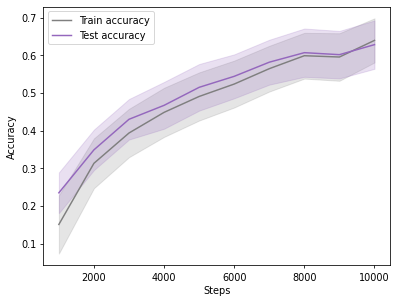

In [11]:
mobnet_model_st_time = time.time() # I wanted to track how long it takes to actually run this so i can measure computation required too

# keep within our optimisation step budget
while steps < 10000:

    # arrays for metrics
    train_loss_arr = np.zeros(0)
    train_acc_arr = np.zeros(0)
    test_acc_arr = np.zeros(0)

    # Training phase:
    model.train()  # important for BatchNorm
    for i in range(1000):
        try: # I have to have this try-catch as v2 was a LOT quicker, and hit the floor of the training data quickly, crashing program
            x, t = next(train_iterator)
        except StopIteration:
            train_iterator = iter(train_loader)
            x, t = next(train_iterator)
        
        # moving both of these to GPU straight after pulling another batch
        x=x.to(device)
        t=t.to(device)

        optimiser.zero_grad(set_to_none=True)
        outputs = model(x)
        loss = F.cross_entropy(outputs, t)
        loss.backward()
        optimiser.step()
        # calling this once/optimisation step is what's boosted my accuracy so far (i.e. a cosine learning rate)
        scheduler.step()  # [DEV NOTE]: toggle on only if using SGD (not Adam)
        steps += 1
        
        # I added this adaptive learning rate in to deal with mild underfitting
        if steps == 8000:
            optimiser = torch.optim.SGD(
                model.parameters(),
                lr=0.02,  # this helps the train/test lines to converge nicer towards the last 2k steps
                momentum=0.9,
                weight_decay=3e-4
            )
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimiser,
                T_max=2000  # only last 2k steps though
            )

        # compute training accuracy
        preds = outputs.argmax(dim=1, keepdim=True)
        acc = preds.eq(t.view_as(preds)).float().mean().item()

        train_loss_arr = np.append(train_loss_arr, loss.detach().cpu().item())
        train_acc_arr = np.append(train_acc_arr, acc)

        if steps >= 10000:
            break  # stop once we hit step budget

            
            
    # Evaluation Phase
    # Credit: Assignment brief template, has only been adapted a little bit to display time (out of interest)
    model.eval()  
    with torch.no_grad():
        for x, t in test_loader:
            x, t = x.to(device), t.to(device)
            outputs = model(x)
            preds = outputs.argmax(dim=1, keepdim=True)
            acc = preds.eq(t.view_as(preds)).float().mean().item()
            test_acc_arr = np.append(test_acc_arr, acc)

    # these logging steps were written in the original DL coursework example code; replicating here for report
    print('steps: {:.0f}, train loss: {:.3f}, train acc: {:.3f}±{:.3f}, test acc: {:.3f}±{:.3f}'.format(
        steps,
        train_loss_arr.mean(),
        train_acc_arr.mean(), train_acc_arr.std(),
        test_acc_arr.mean(), test_acc_arr.std()
    ))
    print('mobnet adapted time elapsed: {:.2f} seconds'.format(time.time() - mobnet_model_st_time))  # and then display how long the mobnet-adapted model took to execute

    # similarly this accuracy plot was taken from the dl coursework example & needed for same reason
    plot_data.append([
        steps,
        train_acc_arr.mean(), train_acc_arr.std(),
        test_acc_arr.mean(), test_acc_arr.std()
    ])
    plt.plot([x[0] for x in plot_data],
             [x[1] for x in plot_data],
             '-', color='tab:grey', label="Train accuracy")
    plt.fill_between([x[0] for x in plot_data],
                     [x[1]-x[2] for x in plot_data],
                     [x[1]+x[2] for x in plot_data],
                     alpha=0.2, color='tab:grey')
    plt.plot([x[0] for x in plot_data],
             [x[3] for x in plot_data],
             '-', color='tab:purple', label="Test accuracy")
    plt.fill_between([x[0] for x in plot_data],
                     [x[3]-x[4] for x in plot_data],
                     [x[3]+x[4] for x in plot_data],
                     alpha=0.2, color='tab:purple')
    plt.xlabel('Steps')
    plt.ylabel('Accuracy')
    plt.legend(loc="upper left")
    plt.show()
    disp.clear_output(wait=True)
    


# Visual Evaluation

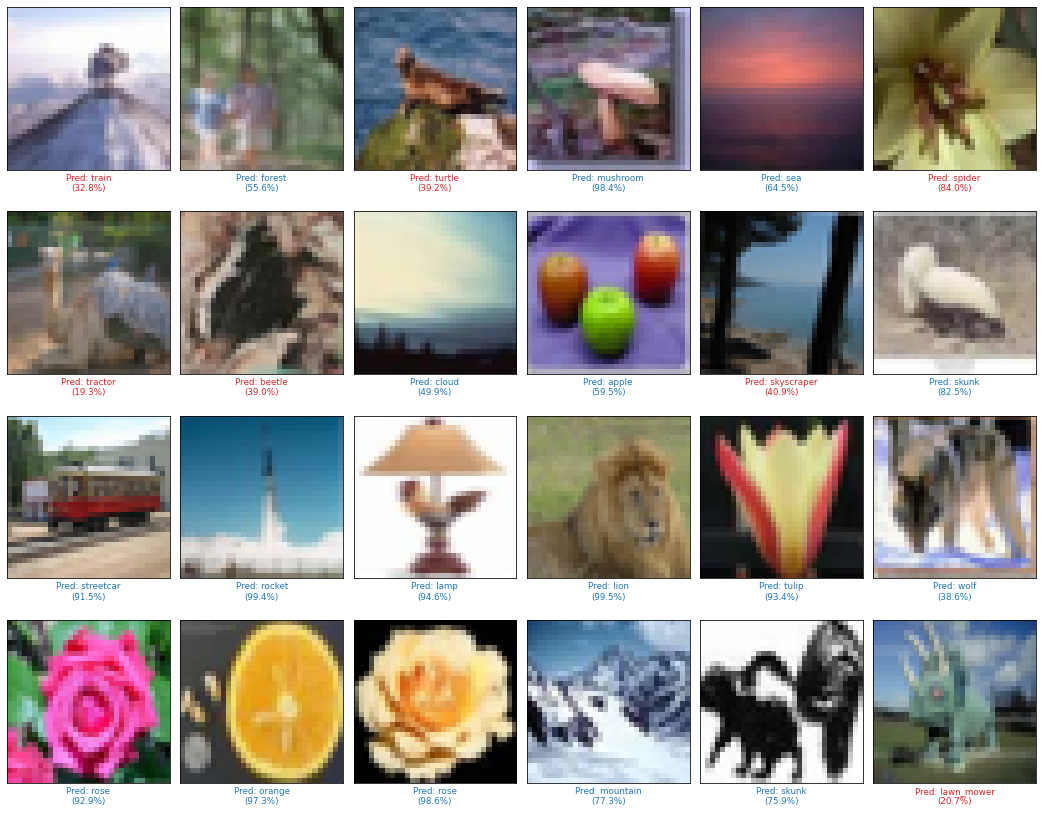

In [12]:
# CREDIT: Slightly adapted version of what was provided by the DL coursework template

# test batch predications
model.eval()
test_images, test_labels = next(test_iterator)
test_images_gpu, test_labels_gpu = test_images.to(device), test_labels.to(device)

with torch.no_grad():
    logits = model(test_images_gpu)
    test_preds = torch.softmax(logits, dim=1).cpu().numpy()

# result plot
num_rows, num_cols = 4, 6 # Adjusted for a standard grid layout
plt.figure(figsize=(15, 12))

for i in range(num_rows * num_cols):
    plt.subplot(num_rows, num_cols, i + 1)
    plt.xticks([])
    plt.yticks([])
    
    # Normalise image dimensions from [C, H, W] to [H, W, C] for pyplot
    img = test_images[i].numpy().transpose(1, 2, 0)
    plt.imshow(img)

    pred_idx = np.argmax(test_preds[i])
    true_idx = test_labels[i].item()
    confidence = 100 * test_preds[i][pred_idx]

    # Visual feedback: blue for correct classification, red for errors
    color = 'tab:blue' if pred_idx == true_idx else 'tab:red'
    
    plt.xlabel(f"Pred: {class_names[pred_idx]}\n({confidence:.1f}%)", color=color, fontsize=9)

plt.tight_layout()
plt.show()